<a href="https://colab.research.google.com/github/PaoloniCoder/MozartAI/blob/m1-dataset-vocabolario/m1_dataset_vocabolario.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget -O /content/CameraPrIMuS.tgz "https://grfia.dlsi.ua.es/primus/packages/primusCalvoRizoAppliedSciences2018.tgz"
!mkdir -p /content/data
!tar -xzf /content/CameraPrIMuS.tgz -C /content/data

--2026-10-28 07:49:38--  https://grfia.dlsi.ua.es/primus/packages/primusCalvoRizoAppliedSciences2018.tgz
Resolving grfia.dlsi.ua.es (grfia.dlsi.ua.es)... 193.145.231.49
Connecting to grfia.dlsi.ua.es (grfia.dlsi.ua.es)|193.145.231.49|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 273645577 (261M) [application/x-gzip]
Saving to: ‘/content/CameraPrIMuS.tgz’

/content/CameraPrIM 100%[===================>] 260.97M  5.56MB/s    in 33s     

2026-10-28 07:50:11 (7.93 MB/s) - ‘/content/CameraPrIMuS.tgz’ saved [273645577/273645577]



In [2]:
import os
import json
from collections import Counter
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!ls /content/data | head
!du -sh /content/data

package_aa
package_ab
4.0G	/content/data


In [4]:
semantic_files = []
for root, dirs, files in os.walk('/content/data'):
    for f in files:
        if f.endswith('.semantic'):
            semantic_files.append(os.path.join(root, f))

semantic_files.sort()   # ordine fisso: i risultati sono sempre gli stessi
print("Esempi trovati:", len(semantic_files))
assert len(semantic_files) > 0, "Nessun file .semantic trovato: controlla con  !ls /content/data"

cartella = os.path.dirname(semantic_files[0])
print("Cartella del primo esempio:", cartella)
print("File contenuti:")
for nome in sorted(os.listdir(cartella)):
    print(" -", nome)


Esempi trovati: 87678
Cartella del primo esempio: /content/data/package_aa/000051650-1_1_1
File contenuti:
 - ._000051650-1_1_1.mei
 - ._000051650-1_1_1.mid
 - ._000051650-1_1_1.png
 - ._regular_pae.pae
 - 000051650-1_1_1.agnostic
 - 000051650-1_1_1.mei
 - 000051650-1_1_1.mid
 - 000051650-1_1_1.png
 - 000051650-1_1_1.semantic
 - regular_pae.pae


Immagine usata: 000051650-1_1_1.png


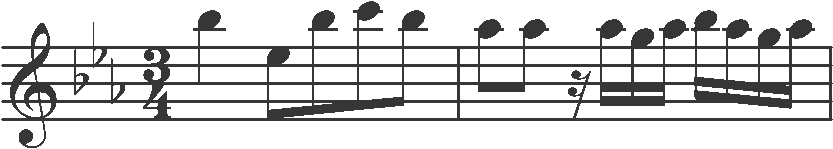

Come è scritto il file (repr mostra anche tab e a capo):
'clef-G2\tkeySignature-EbM\ttimeSignature-3/4\tnote-Bb5_quarter\tnote-Eb5_eighth\tnote-Bb5_eighth\tnote-C6_eighth\tnote-Bb5_eighth\tbarline\tnote-Ab5_eighth\tnote-Ab5_eighth\trest-sixteenth\tnote-Ab5_sixteenth\tnote-G5_sixteenth\tnote-Ab5_sixteenth\tnote-Bb5_sixteenth\tnote-Ab5_sixteenth\tnote-G5_sixteenth\tnote-Ab5_sixteenth\tbarline\t'
Spezzato in simboli:
['clef-G2', 'keySignature-EbM', 'timeSignature-3/4', 'note-Bb5_quarter', 'note-Eb5_eighth', 'note-Bb5_eighth', 'note-C6_eighth', 'note-Bb5_eighth', 'barline', 'note-Ab5_eighth', 'note-Ab5_eighth', 'rest-sixteenth', 'note-Ab5_sixteenth', 'note-G5_sixteenth', 'note-Ab5_sixteenth', 'note-Bb5_sixteenth', 'note-Ab5_sixteenth', 'note-G5_sixteenth', 'note-Ab5_sixteenth', 'barline']


In [5]:
from PIL import Image
from IPython.display import display

sem_path = semantic_files[0]
cartella = os.path.dirname(sem_path)

# Preferisco l'immagine "distorted" se esiste (simula una foto)
immagini = [f for f in os.listdir(cartella) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
immagini.sort(key=lambda f: 'distorted' not in f)
img_path = os.path.join(cartella, immagini[0])
print("Immagine usata:", immagini[0])
display(Image.open(img_path))

testo = open(sem_path, encoding='utf-8').read()
print("Come è scritto il file (repr mostra anche tab e a capo):")
print(repr(testo))
print("Spezzato in simboli:")
print(testo.split())

In [6]:
conteggio = Counter()
lunghezza_max = 0

for path in semantic_files:
    simboli = open(path, encoding='utf-8').read().split()
    conteggio.update(simboli)
    lunghezza_max = max(lunghezza_max, len(simboli))

vocab = sorted(conteggio)                                      # ordinati: numeri sempre uguali
tok2id = {simbolo: i + 1 for i, simbolo in enumerate(vocab)}   # parte da 1: lo 0 è il blank
id2tok = {i: simbolo for simbolo, i in tok2id.items()}

print("Simboli diversi:", len(vocab))
print("Sequenza più lunga:", lunghezza_max)

Simboli diversi: 1781
Sequenza più lunga: 58


In [7]:
cartella_drive = '/content/drive/MyDrive/spartiti/m1'
os.makedirs(cartella_drive, exist_ok=True)

with open(cartella_drive + '/vocab.json', 'w', encoding='utf-8') as f:
    json.dump(tok2id, f, ensure_ascii=False, indent=1)

# Verifica: ricarico il file e controllo che sia uguale a quello in memoria
with open(cartella_drive + '/vocab.json', encoding='utf-8') as f:
    ricaricato = json.load(f)
print("Salvato correttamente:", ricaricato == tok2id)

Salvato correttamente: True


cella 8 da usare

In [8]:

print("Simboli diversi (senza blank):", len(vocab))
print("Classi totali per il modello (con blank):", len(vocab) + 1)
print("Sequenza più lunga:", lunghezza_max)

Simboli diversi (senza blank): 1781
Classi totali per il modello (con blank): 1782
Sequenza più lunga: 58


In [9]:
print("I 10 simboli più frequenti:")
for simbolo, n in conteggio.most_common(10):
    print(f"  {simbolo}: {n}")

n_note = sum(1 for s in vocab if s.startswith('note-'))
print("Simboli diversi che sono note:", n_note, "su", len(vocab))

I 10 simboli più frequenti:
  barline: 326984
  note-D5_eighth: 55010
  rest-quarter: 49597
  clef-G2: 48281
  rest-eighth: 46281
  note-A4_eighth: 45582
  note-C5_eighth: 45453
  note-G4_eighth: 35712
  note-D5_quarter: 34432
  timeSignature-C: 32244
Simboli diversi che sono note: 1384 su 1781
